In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

IMODULON_DIR = DATA_DIR / "imodulondb"
REGULON_DIR = DATA_DIR / "regulondb"
STRING_DIR = DATA_DIR / "string"

# iModulonDB
GENE_INFO_FILE = IMODULON_DIR / "precise_mg1655-gene_info.csv"
EXPRESSION_FILE = IMODULON_DIR / "precise_mg1655-log_tpm.csv"
SAMPLE_FILE = IMODULON_DIR / "precise_mg1655-sample_table.csv"
TRN_FILE = IMODULON_DIR / "precise_mg1655-trn.csv"

# STRING
STRING_FILE = STRING_DIR / "511145.protein.physical.links.full.v12.5.txt.gz"

# RegulonDB
REGULON_FILE = REGULON_DIR / "NetworkRegulatorGene.tsv"
GENE_PRODUCT_FILE = REGULON_DIR / "GeneProductSet.tsv"

# Load the data
gene_info_df = pd.read_csv(GENE_INFO_FILE)
expression_df = pd.read_csv(EXPRESSION_FILE)
sample_df = pd.read_csv(SAMPLE_FILE)
trn_df = pd.read_csv(TRN_FILE)
string_df = pd.read_csv(
    STRING_FILE,
    sep=r"\s+"
)

#print the shape of the dataframes
datasets = {
    "Gene info": gene_info_df,
    "Expression": expression_df,
    "Sample metadata": sample_df,
    "iModulonDB TRN": trn_df,
    "STRING": string_df
}

for name, df in datasets.items():
    print(f"{name:20s} {df.shape}")

Gene info            (4305, 10)
Expression           (4305, 587)
Sample metadata      (586, 59)
iModulonDB TRN       (10773, 8)
STRING               (93708, 10)


In [2]:
gene_info_df.head()

,gene_id,gene_name,gene_product,start,end,strand,uniprot_id,cog,string_id,gene_synonyms
0,b0001,thrL,thr operon leader peptide,190,255,+,P0AD86,No COG annotation,511145.b0001,NaN
1,b0002,thrA,fused aspartate kinase\/homoserine dehydrogena...,337,2799,+,P00561,Amino acid transport and metabolism,511145.b0002,NaN
2,b0003,thrB,homoserine kinase,2801,3733,+,P00547,Nucleotide transport and metabolism,511145.b0003,NaN
3,b0004,thrC,threonine synthase,3734,5020,+,P00934,Amino acid transport and metabolism,511145.b0004,NaN
4,b0005,yaaX,DUF2502 domain-containing protein YaaX,5234,5530,+,P75616,Function unknown,511145.b0005,NaN


In [3]:
expression_df.head()

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430


In [4]:
sample_df.head()

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
trn_df.head()

,regulator_id,regulator_name,target_id,target_name,effect,magnitude,source,evidence
0,b3243,AaeR,b3240,aaeB,activation,NaN,RegulonDB_TF,0.0
1,b3243,AaeR,b3241,aaeA,activation,NaN,RegulonDB_TF,0.0
2,b3243,AaeR,b3242,aaeX,activation,NaN,RegulonDB_TF,0.0
3,b3255,AccB,b3255,accB,repression,NaN,RegulonDB_TF,0.0
4,b3255,AccB,b3256,accC,repression,NaN,RegulonDB_TF,0.0


In [6]:
string_df.head()

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338


In [7]:
# Filter STRING network using different confidence cutoffs
cutoffs = [150, 400, 700, 900]

string_filtered = {}

for cutoff in cutoffs:
    
    df = string_df[
        string_df["combined_score"] >= cutoff
    ].copy()
    
    string_filtered[cutoff] = df
    
    print(
        f"Cutoff {cutoff}: "
        f"{len(df)} interactions"
    )

Cutoff 150: 93708 interactions
Cutoff 400: 57368 interactions
Cutoff 700: 21966 interactions
Cutoff 900: 16244 interactions


In [8]:
# cutoff = 400
# Filter and clean STRING physical interaction network

string_df_filtered = (
    string_df.loc[
        string_df["combined_score"] >= 400, # change the cutoff and just directly run all
        ["protein1", "protein2", "combined_score"]
    ]
    .copy()
)

# Remove the "511145." prefix
string_df_filtered["protein1"] = (
    string_df_filtered["protein1"]
    .str.replace("511145.", "", regex=False)
)

string_df_filtered["protein2"] = (
    string_df_filtered["protein2"]
    .str.replace("511145.", "", regex=False)
)

# Create an undirected protein pair
string_df_filtered[["protein1", "protein2"]] = np.sort(
    string_df_filtered[["protein1", "protein2"]].values,
    axis=1
)

# Remove reciprocal duplicate interactions
string_df_filtered = (
    string_df_filtered
    .drop_duplicates(subset=["protein1", "protein2"])
    .reset_index(drop=True)
)

print("Shape:", string_df_filtered.shape)
string_df_filtered.head()

Shape: (28684, 3)


,protein1,protein2,combined_score
0,b0002,b0436,456
1,b0002,b1945,775
2,b0002,b3940,988
3,b0002,b4024,900
4,b0008,b2464,900


In [9]:
# check if proteins in STRING network are present in the expression_df
string_proteins = set(
    pd.concat([
        string_df_filtered["protein1"],
        string_df_filtered["protein2"]
    ]).unique()
)

# All genes in the expression dataset
expression_genes = set(expression_df["gene_id"])

# Matched and unmatched proteins
matched_proteins = string_proteins & expression_genes
unmatched_proteins = string_proteins - expression_genes

print("STRING proteins:", len(string_proteins))
print("Matched with expression data:", len(matched_proteins))
print("Not matched:", len(unmatched_proteins))
print("Match rate:", len(matched_proteins) / len(string_proteins) * 100, "%")

STRING proteins: 2251
Matched with expression data: 2251
Not matched: 0
Match rate: 100.0 %


In [10]:
# calculation of the degree
protein_degree_df = (
    pd.concat([
        string_df_filtered["protein1"],
        string_df_filtered["protein2"]
    ])
    .value_counts()
    .rename_axis("gene_id")
    .reset_index(name="degree")
)

# Merge degree with expression data
expression_degree_df = expression_df.merge(
    protein_degree_df,
    on="gene_id",
    how="inner"
)

# Move degree directly after gene_id
cols = expression_degree_df.columns.tolist()
cols.remove("degree")
cols.insert(1, "degree")

expression_degree_df = expression_degree_df[cols]

print("Shape:", expression_degree_df.shape)

expression_degree_df.head()

Shape: (2251, 588)


,gene_id,degree,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0002,4,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
1,b0008,3,-0.142828,-0.652939,1.365931,0.635379,0.603098,1.111408,1.018034,0.208408,...,0.112757,0.266787,0.186043,-0.297909,-0.259931,0.948028,1.036374,0.993569,1.049810,1.447697
2,b0009,4,-0.142569,-1.392046,1.201413,1.163233,1.136169,1.284574,1.392161,-0.398936,...,-0.681286,0.048930,-0.518525,0.241266,-0.059813,1.183566,1.097356,0.977128,1.603740,1.037476
3,b0014,26,-0.225867,-0.381914,-1.741237,0.828475,0.847240,-0.612834,-0.682152,0.334997,...,-0.905977,0.604662,0.529396,0.309448,-0.247685,-0.510368,-0.607535,-0.021575,0.043524,-1.634491
4,b0015,29,-0.155054,-0.998241,-0.961966,1.158422,1.227208,0.674104,0.584749,0.671190,...,-0.805394,0.729521,0.646539,0.377724,-0.127264,-0.360727,-0.288270,0.638324,0.681661,-0.988455


In [11]:
string_df_filtered.duplicated(
    subset=["protein1", "protein2"]
).sum()

np.int64(0)

In [12]:
# Calculate expression covariance between interacting proteins
# Use gene_id as index for easy expression lookup
expression_lookup = expression_df.set_index("gene_id")

# Calculate covariance for each protein pair
covariance_results = []

for _, row in string_df_filtered.iterrows():
    
    protein1 = row["protein1"]
    protein2 = row["protein2"]
    
    if protein1 in expression_lookup.index and protein2 in expression_lookup.index:
        
        expression1 = expression_lookup.loc[protein1].values.astype(float)
        expression2 = expression_lookup.loc[protein2].values.astype(float)
        
        covariance = np.cov(expression1, expression2)[0, 1]
        
        covariance_results.append({
            "protein1": protein1,
            "protein2": protein2,
            "covariance": covariance
        })

# Convert results to DataFrame
protein_covariance_df = pd.DataFrame(covariance_results)

print("Shape:", protein_covariance_df.shape)
protein_covariance_df.head()

Shape: (28684, 3)


,protein1,protein2,covariance
0,b0002,b0436,0.528515
1,b0002,b1945,0.152263
2,b0002,b3940,0.414198
3,b0002,b4024,1.299114
4,b0008,b2464,0.310870


In [13]:
# Calculate Pearson and Spearman correlations between interacting protein pairs
from scipy.stats import pearsonr, spearmanr
# *Pearson correlation*
# measures the strength of a linear relationship, ranging from -1 to 1. 
# positive value: 2 genes tend to increase or decrease together across environments; 
# negative: change in opposite directions. 
# close to 0: little linear association. 
# *Spearman correlation*
# measures the strength of a monotonic relationship, ranging from -1 to 1.
# close to 0: little monotonic association.

# Use gene_id as index for easy expression lookup
expression_lookup = expression_df.set_index("gene_id")

correlation_results = []

for _, row in string_df_filtered.iterrows():

    protein1 = row["protein1"]
    protein2 = row["protein2"]

    # Only use pairs where both proteins have expression data
    if protein1 in expression_lookup.index and protein2 in expression_lookup.index:

        expression1 = expression_lookup.loc[protein1].values.astype(float)
        expression2 = expression_lookup.loc[protein2].values.astype(float)

        # Pearson correlation
        pearson_r, _ = pearsonr(expression1, expression2)

        # Spearman correlation
        spearman_rho, _ = spearmanr(expression1, expression2)

        correlation_results.append({
            "protein1": protein1,
            "protein2": protein2,
            "pearson_correlation": pearson_r,
            "spearman_correlation": spearman_rho
        })

# Create pair-level correlation dataset
protein_correlation_df = pd.DataFrame(correlation_results)

print("Shape:", protein_correlation_df.shape)
protein_correlation_df.head()

Shape: (28684, 4)


,protein1,protein2,pearson_correlation,spearman_correlation
0,b0002,b0436,0.395852,0.034371
1,b0002,b1945,0.052565,-0.020246
2,b0002,b3940,0.413680,0.302101
3,b0002,b4024,0.680709,0.428736
4,b0008,b2464,0.205923,0.236768


In [14]:
# Calculate mean partner correlations for each protein and combine with degree
# Calculate mean Pearson and Spearman correlation for each protein
mean_correlation_df = (
    protein_correlation_df
    .groupby("protein1")
    .agg(
        mean_pearson_correlation=("pearson_correlation", "mean"),
        mean_spearman_correlation=("spearman_correlation", "mean")
    )
    .reset_index()
    .rename(columns={"protein1": "gene_id"})
)

# Combine with protein degree
protein_summary_df = protein_degree_df.merge(
    mean_correlation_df,
    on="gene_id",
    how="inner"
)

print("Shape:", protein_summary_df.shape)
protein_summary_df.head()

Shape: (1750, 4)


,gene_id,degree,mean_pearson_correlation,mean_spearman_correlation
0,b2417,197,0.032182,-0.059739
1,b3751,197,0.222753,0.149543
2,b3725,196,0.139719,0.142217
3,b1117,191,0.204123,0.215596
4,b4035,190,-0.127811,-0.184662


Mean Pearson correlation
Pearson r     = -0.1169 (p = 9.373e-07)
Spearman rho  = -0.1008 (p = 2.410e-05)
R²            = 0.0137



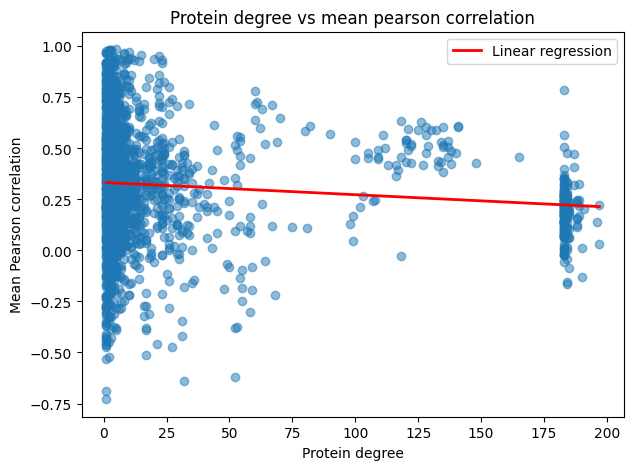

Mean Spearman correlation
Pearson r     = -0.0839 (p = 4.439e-04)
Spearman rho  = -0.0751 (p = 1.661e-03)
R²            = 0.0070



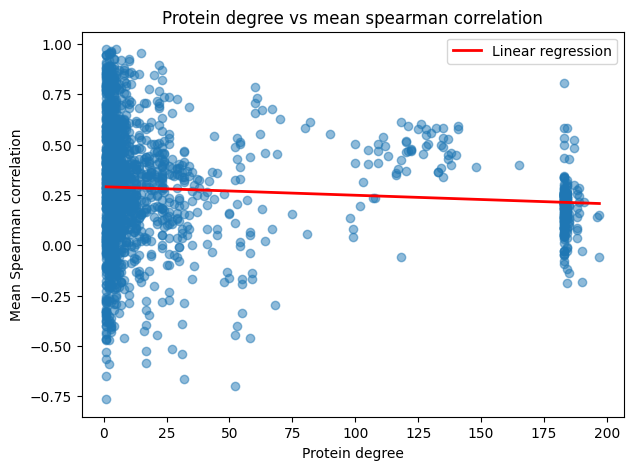

In [15]:
# Degree vs mean partner correlation
# Pearson and Spearman expression measures
from scipy.stats import pearsonr, spearmanr, linregress

# Variables to analyse
correlation_columns = [
    ("mean_pearson_correlation", "Mean Pearson correlation"),
    ("mean_spearman_correlation", "Mean Spearman correlation")
]

for column, ylabel in correlation_columns:

    x = protein_summary_df["degree"]
    y = protein_summary_df[column]

    # Association between degree and mean partner correlation
    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    # Linear regression
    regression = linregress(x, y)
    r_squared = regression.rvalue ** 2

    # Print statistics
    print(f"{ylabel}")
    print(f"Pearson r     = {pearson_r:.4f} (p = {pearson_p:.3e})")
    print(f"Spearman rho  = {spearman_rho:.4f} (p = {spearman_p:.3e})")
    print(f"R²            = {r_squared:.4f}")
    print()

    # Plot
    plt.figure(figsize=(7, 5))

    plt.scatter(
        x,
        y,
        alpha=0.5
    )

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = regression.intercept + regression.slope * x_line

    plt.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label="Linear regression"
    )

    plt.xlabel("Protein degree")
    plt.ylabel(ylabel)
    plt.title(f"Protein degree vs {ylabel.lower()}")
    plt.legend()
    plt.show()
    
# 1. Proteins with low degree show a very wide range of mean correlations, 
# including strongly positive, near-zero, and negative values. 
# This indicates that proteins with only a few interaction partners can have 
# very different levels of expression coordination with their partners.
# 2. At intermediate degrees, several groups of proteins appear to cluster 
# around relatively high mean correlations (approximately 0.35–0.5). 

In [16]:
# Build protein-partner table from the undirected STRING network
protein_partner_df = pd.concat([
    string_df_filtered[
        ["protein1", "protein2"]
    ].rename(columns={
        "protein1": "protein",
        "protein2": "partner"
    }),

    string_df_filtered[
        ["protein1", "protein2"]
    ].rename(columns={
        "protein2": "protein",
        "protein1": "partner"
    })
], ignore_index=True)

# Safety check: one unique partner per protein
protein_partner_df = protein_partner_df.drop_duplicates(
    subset=["protein", "partner"]
)

# Add COG function of each partner
protein_partner_function_df = protein_partner_df.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="partner",
    right_on="gene_id",
    how="left"
)

protein_partner_function_df = (
    protein_partner_function_df
    .drop(columns="gene_id")
    .rename(columns={
        "gene_name": "partner_gene_name",
        "gene_product": "partner_gene_product",
        "cog": "partner_function"
    })
)

protein_partner_function_df.head(10)

,protein,partner,partner_gene_name,partner_gene_product,partner_function
0,b0002,b0436,tig,trigger factor,"Cell cycle control, cell division, chromosome ..."
1,b0002,b1945,fliM,flagellar motor switch protein FliM,Cell motility
2,b0002,b3940,metL,fused aspartate kinase\/homoserine dehydrogena...,Amino acid transport and metabolism
3,b0002,b4024,lysC,aspartate kinase III,Amino acid transport and metabolism
4,b0008,b2464,talA,transaldolase A,Nucleotide transport and metabolism
5,b0008,b2465,tktB,transketolase 2,Carbohydrate transport and metabolism
6,b0008,b3781,trxA,thioredoxin 1,"Post-translational modification, protein turno..."
7,b0009,b0782,moaB,protein MoaB,Coenzyme transport and metabolism
8,b0009,b0827,moeA,molybdopterin molybdotransferase,Coenzyme transport and metabolism
9,b0009,b1727,hxpB,hexitol phosphatase B,Function unknown


In [17]:
# Create pair key for matching protein pairs
protein_partner_function_df["pair_key"] = (
    protein_partner_function_df[["protein", "partner"]]
    .apply(lambda x: tuple(sorted(x)), axis=1)
)

protein_correlation_df["pair_key"] = (
    protein_correlation_df[["protein1", "protein2"]]
    .apply(lambda x: tuple(sorted(x)), axis=1)
)


# Add Pearson and Spearman correlation to each protein-partner pair
functional_pair_df = protein_partner_function_df.merge(
    protein_correlation_df[
        ["pair_key", "pearson_correlation", "spearman_correlation"]
    ],
    on="pair_key",
    how="left"
)


# Summarize for each protein × partner function
functional_summary_df = (
    functional_pair_df
    .groupby(["protein", "partner_function"])
    .agg(
        function_degree=("partner", "nunique"),
        mean_pearson=("pearson_correlation", "mean"),
        mean_spearman=("spearman_correlation", "mean")
    )
    .reset_index()
)

functional_summary_df.head()

,protein,partner_function,function_degree,mean_pearson,mean_spearman
0,b0002,Amino acid transport and metabolism,2,0.547195,0.365418
1,b0002,"Cell cycle control, cell division, chromosome ...",1,0.395852,0.034371
2,b0002,Cell motility,1,0.052565,-0.020246
3,b0008,Carbohydrate transport and metabolism,1,0.228100,0.243342
4,b0008,Nucleotide transport and metabolism,1,0.205923,0.236768


In [18]:
from scipy.stats import spearmanr
import pandas as pd
function_results = []

for function_name, group in functional_summary_df.groupby("partner_function"):

    # Need at least several proteins
    if len(group) < 10:
        continue

    # Skip functions where functional degree is constant
    if group["function_degree"].nunique() < 2:
        continue

    rho, p_value = spearmanr(
        group["function_degree"],
        group["mean_spearman"]
    )

    function_results.append({
        "partner_function": function_name,
        "n_proteins": len(group),
        "spearman_rho": rho,
        "p_value": p_value
    })


function_results_df = pd.DataFrame(function_results)
function_results_df.sort_values("spearman_rho")

,partner_function,n_proteins,spearman_rho,p_value
17,Signal transduction mechanisms,194,-0.212266,2.964866e-03
1,Carbohydrate transport and metabolism,431,-0.188887,7.960868e-05
4,Cell wall\/membrane\/envelope biogenesis,445,-0.109013,2.144652e-02
9,Inorganic ion transport and metabolism,440,-0.102305,3.191311e-02
16,"Secondary metabolites biosynthesis, transport,...",43,-0.085173,5.870960e-01
8,Function unknown,763,-0.071540,4.822255e-02
0,Amino acid transport and metabolism,500,-0.064276,1.512464e-01
10,"Intracellular trafficking, secretion, and vesi...",354,-0.032104,5.471348e-01
6,Defense mechanisms,244,-0.021349,7.400368e-01
18,Transcription,505,0.022426,6.151217e-01


In [19]:
# Cell motility only

function_name = "Cell motility"

function_test_df = functional_summary_df[
    functional_summary_df["partner_function"] == function_name
].copy()

print("Number of proteins:", len(function_test_df))
display(
    function_test_df
    .sort_values("function_degree", ascending=False)
    .head(30)
)

Number of proteins: 153


,protein,partner_function,function_degree,mean_pearson,mean_spearman
2969,b1880,Cell motility,22,0.856632,0.742179
3121,b1949,Cell motility,22,0.907156,0.811051
3123,b1950,Cell motility,21,0.879354,0.759070
1821,b1076,Cell motility,21,0.927912,0.842305
3119,b1948,Cell motility,21,0.938680,0.849749
3113,b1946,Cell motility,21,0.941335,0.841012
2973,b1882,Cell motility,19,0.841943,0.602796
3090,b1938,Cell motility,19,0.941325,0.847839
3109,b1945,Cell motility,19,0.946468,0.871852
1840,b1080,Cell motility,18,0.942158,0.867143


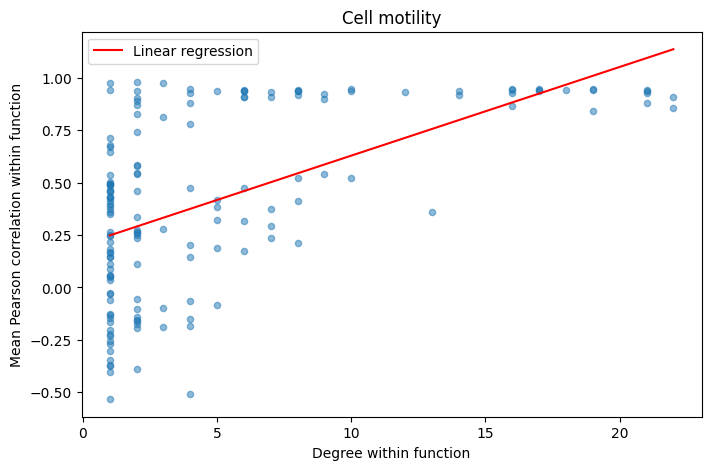

Pearson r: 0.5581065536207711 p = 6.62996180392721e-14
Spearman rho: 0.5606301796118227 p = 4.840599909707756e-14


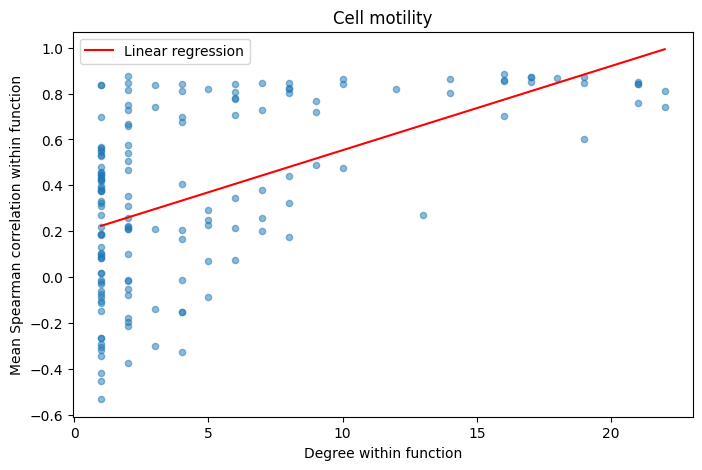

Pearson r: 0.544064809216094 p = 3.6391850976288543e-13
Spearman rho: 0.5444773911907245 p = 3.465483842837507e-13


In [20]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import numpy as np
# Pearson

x = function_test_df["function_degree"]
y = function_test_df["mean_pearson"]

r, p_r = pearsonr(x, y)
rho, p_rho = spearmanr(x, y)

coef = np.polyfit(x, y, 1)
line = np.poly1d(coef)

plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    np.sort(x),
    line(np.sort(x)),
    color="red",
    label="Linear regression"
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Pearson correlation within function")
plt.title("Cell motility")
plt.legend()
plt.show()
print("Pearson r:", r, "p =", p_r)
print("Spearman rho:", rho, "p =", p_rho)


# Spearman
x = function_test_df["function_degree"]
y = function_test_df["mean_spearman"]

r, p_r = pearsonr(x, y)
rho, p_rho = spearmanr(x, y)

coef = np.polyfit(x, y, 1)
line = np.poly1d(coef)

plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    np.sort(x),
    line(np.sort(x)),
    color="red",
    label="Linear regression"
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Spearman correlation within function")
plt.title("Cell motility")
plt.legend()
plt.show()
print("Pearson r:", r, "p =", p_r)
print("Spearman rho:", rho, "p =", p_rho)

In [21]:
# Examine individual partner correlations within Cell motility to check the detail, instead of mean correlations. 
# This will allow us to see if there are any outliers or specific protein-partner pairs that are driving the overall correlation.
import pandas as pd
import matplotlib.pyplot as plt

function_name = "Cell motility"

# 1. Select protein-partner pairs where the partner belongs to Cell motility
cell_motility_pairs = protein_partner_function_df[
    protein_partner_function_df["partner_function"] == function_name
][["protein", "partner"]].copy()


# 2. Create undirected pair keys
# This allows A-B and B-A to be treated as the same interaction
cell_motility_pairs["pair_key"] = cell_motility_pairs[
    ["protein", "partner"]
].apply(lambda x: tuple(sorted(x)), axis=1)

protein_correlation_temp = protein_correlation_df.copy()

protein_correlation_temp["pair_key"] = protein_correlation_temp[
    ["protein1", "protein2"]
].apply(lambda x: tuple(sorted(x)), axis=1)


# 3. Add the individual Pearson and Spearman correlations
cell_motility_individual_df = cell_motility_pairs.merge(
    protein_correlation_temp[
        ["pair_key", "pearson_correlation", "spearman_correlation"]
    ],
    on="pair_key",
    how="left"
)


# 4. Calculate functional degree for each protein
# Number of Cell motility partners connected to that protein
functional_degree = (
    cell_motility_individual_df
    .groupby("protein")["partner"]
    .nunique()
    .rename("function_degree")
)

cell_motility_individual_df = cell_motility_individual_df.merge(
    functional_degree,
    on="protein",
    how="left"
)

# 5. Remove missing correlations（though there shouldn't be any, but just in case）
cell_motility_individual_df = (
    cell_motility_individual_df
    .dropna(subset=["spearman_correlation"])
)

# Check the resulting table
print("Number of interactions:", len(cell_motility_individual_df))
print("Number of proteins:", cell_motility_individual_df["protein"].nunique())
cell_motility_individual_df.head(15)

Number of interactions: 767
Number of proteins: 153


,protein,partner,pair_key,pearson_correlation,spearman_correlation,function_degree
0,b0002,b1945,"(b0002, b1945)",0.052565,-0.020246,1
1,b0047,b1078,"(b0047, b1078)",-0.370329,-0.416372,1
2,b0054,b4558,"(b0054, b4558)",0.678886,0.552750,1
3,b0081,b1077,"(b0081, b1077)",-0.304237,-0.293350,1
4,b0106,b3394,"(b0106, b3394)",0.503105,0.445447,1
5,b0107,b3394,"(b0107, b3394)",0.182497,0.083383,1
6,b0121,b1945,"(b0121, b1945)",0.245981,0.377486,1
7,b0139,b0939,"(b0139, b0939)",0.385732,0.232356,6
8,b0139,b0940,"(b0139, b0940)",0.698676,0.554785,6
9,b0139,b2109,"(b0139, b2109)",0.640873,0.447477,6


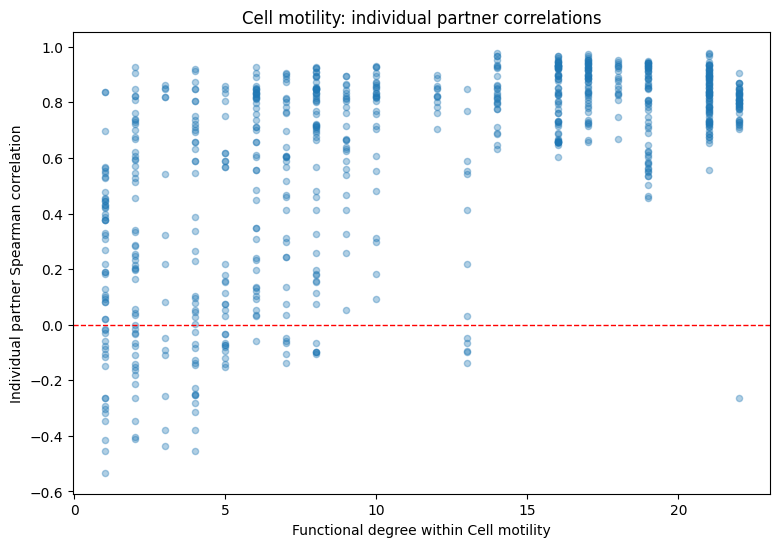

In [22]:
# Plot individual partner correlations against functional degree
plt.figure(figsize=(9, 6))

plt.scatter(
    cell_motility_individual_df["function_degree"],
    cell_motility_individual_df["spearman_correlation"],
    alpha=0.35,
    s=20
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Functional degree within Cell motility")
plt.ylabel("Individual partner Spearman correlation")
plt.title("Cell motility: individual partner correlations")
plt.show()

In [23]:
# Find proteins with high functional degree in Cell motility
high_degree_cell_motility = (
    cell_motility_individual_df[
        cell_motility_individual_df["function_degree"] >= 14
    ][["protein", "function_degree"]]
    .drop_duplicates()
    .sort_values("function_degree", ascending=False)
)

# Add gene annotation
high_degree_cell_motility = high_degree_cell_motility.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="protein",
    right_on="gene_id",
    how="left"
)

high_degree_cell_motility[
    ["protein", "gene_name", "gene_product", "function_degree"]
]

# Most high-functional-degree proteins in the Cell motility group are 
# components of the flagellar machinery, such as FlhB, FliQ, FliR, FliP, FlgE, and FliM.
# These proteins participate in the construction and operation of the same complex molecular machine. 

# Their strongly coordinated expression therefore supports our interpretation that 
# high functional degree can reflect coordinated regulation 
# among proteins working together in a shared molecular structure.

,protein,gene_name,gene_product,function_degree
0,b1880,flhB,flagellar biosynthesis protein FlhB,22
1,b1949,fliQ,flagellar biosynthesis protein FliQ,22
2,b1950,fliR,flagellar biosynthesis protein FliR,21
3,b1948,fliP,flagellar biosynthesis protein FliP,21
4,b1946,fliN,flagellar motor switch protein FliN,21
5,b1076,flgE,flagellar hook protein FlgE,21
6,b1882,cheY,chemotaxis protein CheY,19
7,b1938,fliF,flagellar basal-body MS-ring and collar protein,19
8,b1945,fliM,flagellar motor switch protein FliM,19
9,b1080,flgI,flagellar P-ring protein,18


Selected function:
'Defense mechanisms'

Number of proteins: 244
Spearman rho = -0.0213
p-value = 7.4004e-01


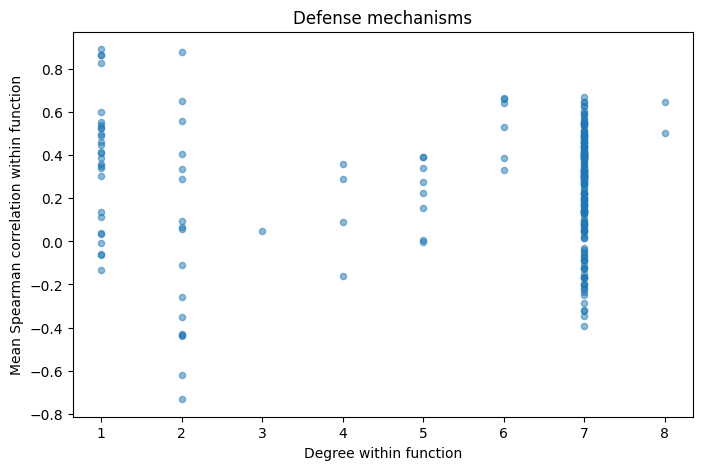

In [24]:
# Select the function with Spearman rho closest to zero
selected_row = function_results_df.loc[
    function_results_df["spearman_rho"].abs().idxmin()
]

function_name = selected_row["partner_function"]

print("Selected function:")
print(repr(function_name))
print()

function_test_df = functional_summary_df[
    functional_summary_df["partner_function"] == function_name
]

print("Number of proteins:", len(function_test_df))

rho, p_value = spearmanr(
    function_test_df["function_degree"],
    function_test_df["mean_spearman"]
)

print(f"Spearman rho = {rho:.4f}")
print(f"p-value = {p_value:.4e}")


plt.figure(figsize=(8, 5))

plt.scatter(
    function_test_df["function_degree"],
    function_test_df["mean_spearman"],
    alpha=0.5,
    s=20
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Spearman correlation within function")
plt.title(function_name)
plt.show()

In [25]:
# Then what whill happen in dataset trn? 
# Explore the TRN dataset
print("Shape:", trn_df.shape)

display(trn_df.head(10))
print("\nMissing values:")
print(trn_df.isna().sum())

Shape: (10773, 8)


,regulator_id,regulator_name,target_id,target_name,effect,magnitude,source,evidence
0,b3243,AaeR,b3240,aaeB,activation,NaN,RegulonDB_TF,0.0
1,b3243,AaeR,b3241,aaeA,activation,NaN,RegulonDB_TF,0.0
2,b3243,AaeR,b3242,aaeX,activation,NaN,RegulonDB_TF,0.0
3,b3255,AccB,b3255,accB,repression,NaN,RegulonDB_TF,0.0
4,b3255,AccB,b3256,accC,repression,NaN,RegulonDB_TF,0.0
5,NaN,AccDA,b0185,accA,repression,NaN,RegulonDB_TF,0.0
6,NaN,AccDA,b2316,accD,repression,NaN,RegulonDB_TF,0.0
7,b0118,AcnB,b0118,acnB,activation,NaN,RegulonDB_TF,0.0
8,b0464,AcrR,b0462,acrB,repression,NaN,RegulonDB_TF,2.0
9,b0464,AcrR,b0463,acrA,repression,NaN,RegulonDB_TF,2.0



Missing values:
regulator_id       2409
regulator_name        0
target_id             0
target_name           0
effect              132
magnitude         10773
source                0
evidence            123
dtype: int64


In [26]:
# Filter TRN dataset
# Evidence cutoff, Set to 0 for no evidence filtering at first
EVIDENCE_CUTOFF = 0

trn_df_filtered = trn_df[
    # Keep interactions with valid regulator and target IDs
    trn_df["regulator_id"].notna()
    & trn_df["target_id"].notna()

    # Evidence cutoff
    & (trn_df["evidence"].fillna(0) >= EVIDENCE_CUTOFF)
].copy()

# Keep only relevant columns
trn_df_filtered = trn_df_filtered[
    [
        "regulator_id",
        "target_id",
        "effect",
        "evidence"
    ]
]

# Remove duplicated regulator-target interactions
trn_df_filtered = trn_df_filtered.drop_duplicates(
    subset=["regulator_id", "target_id"]
)

# Reset index
trn_df_filtered = trn_df_filtered.reset_index(drop=True)

print("Evidence cutoff:", EVIDENCE_CUTOFF)
print("Original interactions:", len(trn_df))
print("Filtered interactions:", len(trn_df_filtered))
print("Unique regulators:", trn_df_filtered["regulator_id"].nunique())
print("Unique targets:", trn_df_filtered["target_id"].nunique())
trn_df_filtered.head(10)

Evidence cutoff: 0
Original interactions: 10773
Filtered interactions: 8364
Unique regulators: 267
Unique targets: 2951


,regulator_id,target_id,effect,evidence
0,b3243,b3240,activation,0.0
1,b3243,b3241,activation,0.0
2,b3243,b3242,activation,0.0
3,b3255,b3255,repression,0.0
4,b3255,b3256,repression,0.0
5,b0118,b0118,activation,0.0
6,b0464,b0462,repression,2.0
7,b0464,b0463,repression,2.0
8,b0464,b0464,repression,2.0
9,b0464,b1297,repression,1.0


In [27]:
# Check matching between TRN genes and expression dataset
expression_genes = set(expression_df["gene_id"])

regulators = set(trn_df_filtered["regulator_id"])
targets = set(trn_df_filtered["target_id"])

matched_regulators = regulators & expression_genes
matched_targets = targets & expression_genes

print("TRN regulators:", len(regulators))
print("Regulators matched with expression:", len(matched_regulators))
print("Regulators not matched:", len(regulators - expression_genes))
print()
print("TRN targets:", len(targets))
print("Targets matched with expression:", len(matched_targets))
print("Targets not matched:", len(targets - expression_genes))

TRN regulators: 267
Regulators matched with expression: 267
Regulators not matched: 0

TRN targets: 2951
Targets matched with expression: 2951
Targets not matched: 0


In [28]:
# Keep regulator-target pairs for which both genes have expression data
trn_expression_pairs_df = trn_df_filtered[
    trn_df_filtered["regulator_id"].isin(expression_genes)
    & trn_df_filtered["target_id"].isin(expression_genes)
].copy()

trn_expression_pairs_df = trn_expression_pairs_df.reset_index(drop=True)

print("TRN interactions before expression matching:",
      len(trn_df_filtered))
print("TRN interactions after expression matching:",
      len(trn_expression_pairs_df))

print(
    "Paring percentage:",
    round(
        len(trn_expression_pairs_df) /
        len(trn_df_filtered) * 100,
        2
    ),
    "%"
)
trn_expression_pairs_df.head(10)

TRN interactions before expression matching: 8364
TRN interactions after expression matching: 8364
Paring percentage: 100.0 %


,regulator_id,target_id,effect,evidence
0,b3243,b3240,activation,0.0
1,b3243,b3241,activation,0.0
2,b3243,b3242,activation,0.0
3,b3255,b3255,repression,0.0
4,b3255,b3256,repression,0.0
5,b0118,b0118,activation,0.0
6,b0464,b0462,repression,2.0
7,b0464,b0463,repression,2.0
8,b0464,b0464,repression,2.0
9,b0464,b1297,repression,1.0


In [29]:
# Calculate TRN regulator out-degree and merge with expression data
# out_degree = number of unique target genes regulated by each regulator

# 1. Calculate out-degree for each regulator
trn_regulator_degree_df = (
    trn_expression_pairs_df
    .groupby("regulator_id")["target_id"]
    .nunique()
    .reset_index(name="out_degree")
)

# 2. Merge regulator out-degree with expression data
trn_expression_degree_df = expression_df.merge(
    trn_regulator_degree_df,
    left_on="gene_id",
    right_on="regulator_id",
    how="inner"
)

# 3. Remove duplicated regulator ID column
trn_expression_degree_df = trn_expression_degree_df.drop(
    columns="regulator_id"
)

# 4. Put out_degree directly after gene_id
cols = [
    "gene_id",
    "out_degree"
] + [
    col for col in trn_expression_degree_df.columns
    if col not in ["gene_id", "out_degree"]
]

trn_expression_degree_df = trn_expression_degree_df[cols]

# 5. Sort by out-degree for inspection
trn_expression_degree_df = (
    trn_expression_degree_df
    .sort_values("out_degree", ascending=False)
    .reset_index(drop=True)
)

print("Number of regulators:", len(trn_regulator_degree_df))
print(
    "Number of regulators matched with expression data:",
    len(trn_expression_degree_df)
)
trn_expression_degree_df.head(10)

Number of regulators: 267
Number of regulators matched with expression data: 267


,gene_id,out_degree,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b3067,1555,-0.209147,-0.932265,-0.173063,0.601176,0.615337,0.720078,0.678671,1.018651,...,-0.672587,0.938780,0.947262,0.945346,0.445352,0.028056,0.122415,0.406491,0.373084,-0.071561
1,b3357,554,-0.030649,-0.754866,0.659754,-0.481493,-0.514577,0.072110,-0.038648,-0.492673,...,1.029533,-0.772132,-0.712887,-0.353881,0.048290,0.826215,0.863579,0.548258,0.647091,0.666312
2,b1988,525,0.523394,1.088812,1.363575,9.377239,9.211228,7.855235,7.802805,8.509614,...,0.393093,-0.176947,-0.302831,-0.069447,0.137881,-0.316193,-0.087528,-0.480731,-0.100976,0.971444
3,b2741,330,-0.229608,-0.025270,-0.009262,1.840724,1.938113,1.679825,1.618709,2.458141,...,1.274982,0.980078,1.054607,1.811728,1.660272,0.269385,0.317355,0.266751,0.355989,0.004897
4,b0889,326,-0.292853,-0.049640,-0.941815,-1.432213,-1.402258,-0.896603,-0.848518,-0.143608,...,-0.084555,-0.548645,-0.581208,-0.315557,-0.124147,-0.596206,-0.503814,-0.499402,-0.415093,-0.970025
5,b1334,318,-0.559259,-0.455790,-1.454673,-0.351243,-0.319465,-0.123365,-0.199458,-0.701507,...,-0.098271,-1.056600,-1.176865,-0.681194,-0.460715,0.150163,-0.094335,-0.009473,0.213666,-1.369748
6,b4401,230,-0.052781,0.039038,1.531386,3.340707,3.457439,1.710758,1.732817,2.245308,...,0.852117,0.599259,0.534527,1.365378,1.455151,1.548757,1.707889,1.231863,1.089807,1.317564
7,b0683,229,-0.128063,-0.376130,1.747679,1.499164,1.649673,1.207082,1.636118,0.439058,...,0.649331,0.445324,0.472295,0.844554,1.144353,0.950134,1.323187,1.135427,0.895129,1.628109
8,b3261,168,0.475844,-2.193151,-0.192257,-0.979638,-0.983602,0.371103,0.399793,-0.469371,...,-0.934347,-0.190781,-0.047214,-0.127645,-0.548204,-0.100650,0.007401,0.707215,0.246663,-0.269661
9,b3202,142,-0.098578,-0.147879,2.130781,2.388465,2.253025,1.928392,1.946514,1.329932,...,-0.025805,0.996201,1.068927,1.119550,0.985276,1.712309,1.805237,1.153278,1.203091,2.084024


In [30]:
# calculation of the correlation between regulator and target expression across all environments
# Expression lookup table
expression_lookup = expression_df.set_index("gene_id")

# All environment / condition columns
expression_columns = expression_df.columns.drop("gene_id")

results = []

for _, row in trn_expression_pairs_df.iterrows():

    regulator = row["regulator_id"]
    target = row["target_id"]

    # Both genes should have expression data
    if regulator not in expression_lookup.index:
        continue

    if target not in expression_lookup.index:
        continue

    # Expression across all environments
    regulator_expression = expression_lookup.loc[
        regulator, expression_columns
    ].astype(float)

    target_expression = expression_lookup.loc[
        target, expression_columns
    ].astype(float)

    # Remove environments containing missing values
    valid = (
        regulator_expression.notna()
        & target_expression.notna()
    )

    x = regulator_expression[valid]
    y = target_expression[valid]

    # Need enough observations and variation
    if len(x) < 3:
        continue

    if x.nunique() < 2 or y.nunique() < 2:
        continue

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    results.append({
        "regulator_id": regulator,
        "target_id": target,
        "effect": row["effect"],
        "evidence": row["evidence"],
        "pearson_correlation": pearson_r,
        "spearman_correlation": spearman_rho
    })


trn_correlation_df = pd.DataFrame(results)
trn_correlation_df.head(10)

,regulator_id,target_id,effect,evidence,pearson_correlation,spearman_correlation
0,b3243,b3240,activation,0.0,0.561556,0.607817
1,b3243,b3241,activation,0.0,0.603308,0.671082
2,b3243,b3242,activation,0.0,0.519287,0.595373
3,b3255,b3255,repression,0.0,1.000000,1.000000
4,b3255,b3256,repression,0.0,0.886127,0.909597
5,b0118,b0118,activation,0.0,1.000000,1.000000
6,b0464,b0462,repression,2.0,0.229424,-0.182954
7,b0464,b0463,repression,2.0,0.092267,-0.012556
8,b0464,b0464,repression,2.0,1.000000,1.000000
9,b0464,b1297,repression,1.0,-0.177726,-0.224967


In [31]:
# Mean correlation of all targets for each regulator
trn_mean_correlation_df = (
    trn_correlation_df
    .groupby("regulator_id")
    .agg(
        mean_pearson_correlation=("pearson_correlation", "mean"),
        mean_spearman_correlation=("spearman_correlation", "mean")
    )
    .reset_index()
)


# Add regulator out-degree

trn_regulator_summary_df = trn_regulator_degree_df.merge(
    trn_mean_correlation_df,
    on="regulator_id",
    how="inner"
)


# Rename regulator_id -> gene_id for consistency
trn_regulator_summary_df = trn_regulator_summary_df.rename(
    columns={"regulator_id": "gene_id"}
)


# Sort by out-degree
trn_regulator_summary_df = (
    trn_regulator_summary_df
    .sort_values("out_degree", ascending=False)
    .reset_index(drop=True)
)

trn_regulator_summary_df.head()

,gene_id,out_degree,mean_pearson_correlation,mean_spearman_correlation
0,b3067,1555,0.061783,0.090169
1,b3357,554,0.211998,0.212499
2,b1988,525,0.135158,0.143086
3,b2741,330,0.413180,0.413306
4,b0889,326,0.083878,-0.023292


Mean Pearson correlation
Pearson r    = -0.1834 (p = 2.626e-03)
Spearman rho = -0.4272 (p = 2.860e-13)
R²           = 0.0336


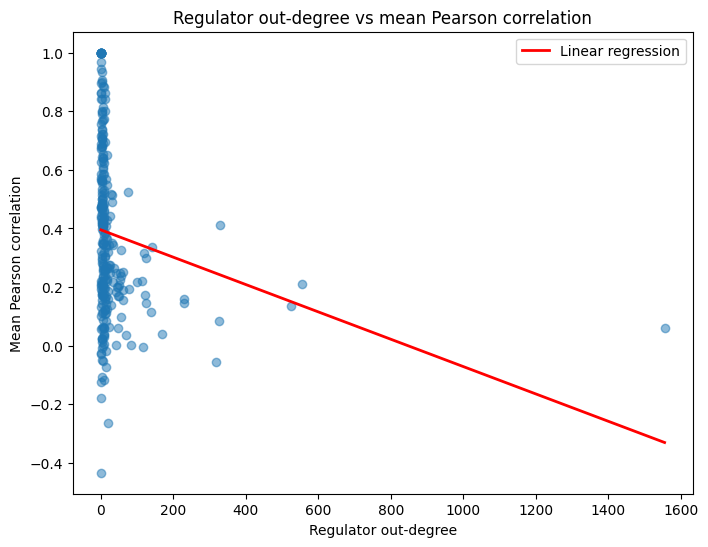


Mean Spearman correlation
Pearson r    = -0.1744 (p = 4.268e-03)
Spearman rho = -0.4364 (p = 7.667e-14)
R²           = 0.0304


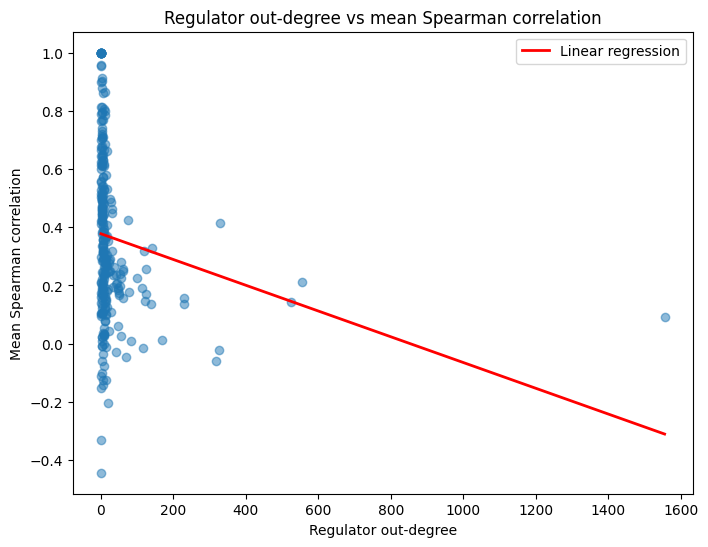

In [32]:
# 1. Out-degree vs mean Pearson correlation
x = trn_regulator_summary_df["out_degree"]
y = trn_regulator_summary_df["mean_pearson_correlation"]

pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

# Linear regression
slope, intercept = np.polyfit(x, y, 1)
y_pred = slope * x + intercept
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)

print("Mean Pearson correlation")
print(f"Pearson r    = {pearson_r:.4f} (p = {pearson_p:.3e})")
print(f"Spearman rho = {spearman_rho:.4f} (p = {spearman_p:.3e})")
print(f"R²           = {r2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(x, y, alpha=0.5)

x_line = np.linspace(x.min(), x.max(), 200)

plt.plot(
    x_line,
    slope * x_line + intercept,
    color="red",
    linewidth=2,
    label="Linear regression"
)

plt.xlabel("Regulator out-degree")
plt.ylabel("Mean Pearson correlation")
plt.title("Regulator out-degree vs mean Pearson correlation")
plt.legend()
plt.show()


# 2. Out-degree vs mean Spearman correlation
x = trn_regulator_summary_df["out_degree"]
y = trn_regulator_summary_df["mean_spearman_correlation"]

pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

# Linear regression
slope, intercept = np.polyfit(x, y, 1)
y_pred = slope * x + intercept
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)

print("\nMean Spearman correlation")
print(f"Pearson r    = {pearson_r:.4f} (p = {pearson_p:.3e})")
print(f"Spearman rho = {spearman_rho:.4f} (p = {spearman_p:.3e})")
print(f"R²           = {r2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(x, y, alpha=0.5)

x_line = np.linspace(x.min(), x.max(), 200)

plt.plot(
    x_line,
    slope * x_line + intercept,
    color="red",
    linewidth=2,
    label="Linear regression"
)

plt.xlabel("Regulator out-degree")
plt.ylabel("Mean Spearman correlation")
plt.title("Regulator out-degree vs mean Spearman correlation")
plt.legend()
plt.show()

In [33]:
# considering the function of the target genes in trn. 
# first step, add target gene function to the TRN
trn_target_function_df = trn_expression_pairs_df.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="target_id",
    right_on="gene_id",
    how="left"
)

# Rename target annotation columns
trn_target_function_df = trn_target_function_df.rename(
    columns={
        "gene_name": "target_gene_name",
        "gene_product": "target_gene_product",
        "cog": "target_function"
    }
)

# Keep only useful columns
trn_target_function_df = trn_target_function_df[
    [
        "regulator_id",
        "target_id",
        "target_gene_name",
        "target_gene_product",
        "target_function",
        "effect",
        "evidence"
    ]
]

trn_target_function_df.head(10)

,regulator_id,target_id,target_gene_name,target_gene_product,target_function,effect,evidence
0,b3243,b3240,aaeB,aromatic carboxylic acid efflux pump subunit AaeB,"Intracellular trafficking, secretion, and vesi...",activation,0.0
1,b3243,b3241,aaeA,aromatic carboxylic acid efflux pump membrane ...,Defense mechanisms,activation,0.0
2,b3243,b3242,aaeX,DUF1656 domain-containing protein AaeX,Function unknown,activation,0.0
3,b3255,b3255,accB,biotin carboxyl carrier protein,Lipid transport and metabolism,repression,0.0
4,b3255,b3256,accC,biotin carboxylase,Lipid transport and metabolism,repression,0.0
5,b0118,b0118,acnB,AcnB,Energy production and conversion,activation,0.0
6,b0464,b0462,acrB,multidrug efflux pump RND permease AcrB,Defense mechanisms,repression,2.0
7,b0464,b0463,acrA,multidrug efflux pump membrane fusion lipoprot...,Cell wall\/membrane\/envelope biogenesis,repression,2.0
8,b0464,b0464,acrR,DNA-binding transcriptional repressor AcrR,Transcription,repression,2.0
9,b0464,b1297,puuA,glutamate-putrescine ligase,Amino acid transport and metabolism,repression,1.0


In [34]:
# step 2, Calculate function-specific out-degree and mean correlations
# Add regulator-target correlations calculated previously
trn_function_pair_df = trn_target_function_df.merge(
    trn_correlation_df[
        [
            "regulator_id",
            "target_id",
            "pearson_correlation",
            "spearman_correlation"
        ]
    ],
    on=["regulator_id", "target_id"],
    how="inner"
)


# Group by regulator + target function
trn_function_summary_df = (
    trn_function_pair_df
    .groupby(
        ["regulator_id", "target_function"],
        dropna=False
    )
    .agg(
        function_out_degree=("target_id", "nunique"),

        mean_pearson_correlation=(
            "pearson_correlation",
            "mean"
        ),

        mean_spearman_correlation=(
            "spearman_correlation",
            "mean"
        )
    )
    .reset_index()
)


# Sort for easier inspection
trn_function_summary_df = (
    trn_function_summary_df
    .sort_values(
        "function_out_degree",
        ascending=False
    )
    .reset_index(drop=True)
)

trn_function_summary_df.head(10)

,regulator_id,target_function,function_out_degree,mean_pearson_correlation,mean_spearman_correlation
0,b3067,Transcription,170,0.052192,0.067379
1,b3067,Energy production and conversion,150,0.072709,0.112594
2,b3067,Inorganic ion transport and metabolism,141,0.039671,0.054245
3,b3067,Function unknown,137,0.105279,0.098312
4,b3067,Nucleotide transport and metabolism,134,0.042331,0.110757
5,b3067,Amino acid transport and metabolism,128,0.027928,0.089534
6,b1988,Function unknown,120,0.143273,0.163671
7,b3067,Carbohydrate transport and metabolism,109,0.042702,0.062215
8,b3357,Carbohydrate transport and metabolism,100,0.234250,0.250129
9,b1334,Energy production and conversion,95,-0.083918,-0.093477


Functional out-degree vs mean Pearson correlation
Pearson r    = -0.1251 (p = 8.332e-07)
Spearman rho = -0.1995 (p = 2.709e-15)
R²           = 0.0157


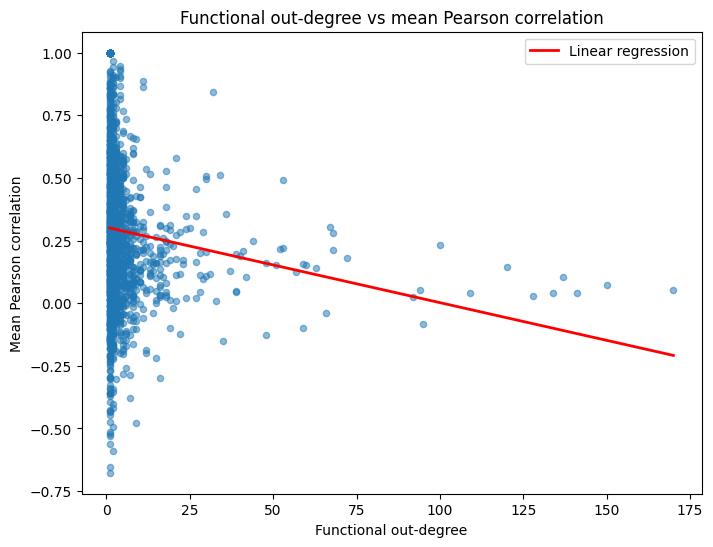


Functional out-degree vs mean Spearman correlation
Pearson r    = -0.1144 (p = 6.675e-06)
Spearman rho = -0.1975 (p = 5.130e-15)
R²           = 0.0131


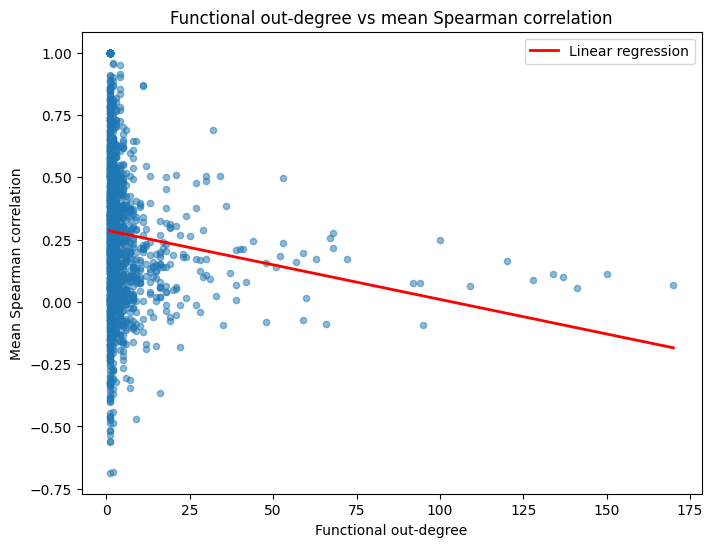

In [ ]:
# 1. Functional out-degree vs mean Pearson correlation

plot_df = trn_function_summary_df.dropna(
    subset=["function_out_degree", "mean_pearson_correlation"]
)

x = plot_df["function_out_degree"].values
y = plot_df["mean_pearson_correlation"].values

# Overall statistics
pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

# Linear regression using numpy
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

# R²
y_pred = slope * x + intercept
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot

print("Functional out-degree vs mean Pearson correlation")
print(f"Pearson r    = {pearson_r:.4f} (p = {pearson_p:.3e})")
print(f"Spearman rho = {spearman_rho:.4f} (p = {spearman_p:.3e})")
print(f"R²           = {r2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Linear regression"
)

plt.xlabel("Functional out-degree")
plt.ylabel("Mean Pearson correlation")
plt.title("Functional out-degree vs mean Pearson correlation")
plt.legend()
plt.show()


# 2. Functional out-degree vs mean Spearman correlation

plot_df = trn_function_summary_df.dropna(
    subset=["function_out_degree", "mean_spearman_correlation"]
)

x = plot_df["function_out_degree"].values
y = plot_df["mean_spearman_correlation"].values

# Overall statistics
pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

# Linear regression
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

# R²
y_pred = slope * x + intercept
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot

print("\nFunctional out-degree vs mean Spearman correlation")
print(f"Pearson r    = {pearson_r:.4f} (p = {pearson_p:.3e})")
print(f"Spearman rho = {spearman_rho:.4f} (p = {spearman_p:.3e})")
print(f"R²           = {r2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Linear regression"
)

plt.xlabel("Functional out-degree")
plt.ylabel("Mean Spearman correlation")
plt.title("Functional out-degree vs mean Spearman correlation")
plt.legend()
plt.show()

In [35]:
# check spearman_rho
function_results = []

for function_name, group in trn_function_summary_df.groupby(
    "target_function"
):

    # Need enough regulators for comparison
    if len(group) < 10:
        continue

    # Degree must vary
    if group["function_out_degree"].nunique() < 2:
        continue

    rho, p_value = spearmanr(
        group["function_out_degree"],
        group["mean_spearman_correlation"]
    )

    function_results.append({
        "target_function": function_name,
        "n_regulators": len(group),
        "spearman_rho": rho,
        "p_value": p_value
    })


trn_function_results_df = pd.DataFrame(
    function_results
).sort_values("spearman_rho")

trn_function_results_df

,target_function,n_regulators,spearman_rho,p_value
18,Transcription,198,-0.655160,1.171766e-25
19,"Translation, ribosomal structure and biogenesis",73,-0.400523,4.460531e-04
11,Lipid transport and metabolism,50,-0.369179,8.330325e-03
3,Cell motility,37,-0.268438,1.081770e-01
7,Energy production and conversion,111,-0.233576,1.361544e-02
17,Signal transduction mechanisms,59,-0.222661,9.006558e-02
13,Nucleotide transport and metabolism,98,-0.190164,6.071980e-02
9,Inorganic ion transport and metabolism,106,-0.175987,7.114956e-02
4,Cell wall\/membrane\/envelope biogenesis,93,-0.153756,1.411607e-01
8,Function unknown,138,-0.115027,1.791324e-01


Number of regulators: 198
Spearman rho = -0.6552
p-value = 1.1718e-25


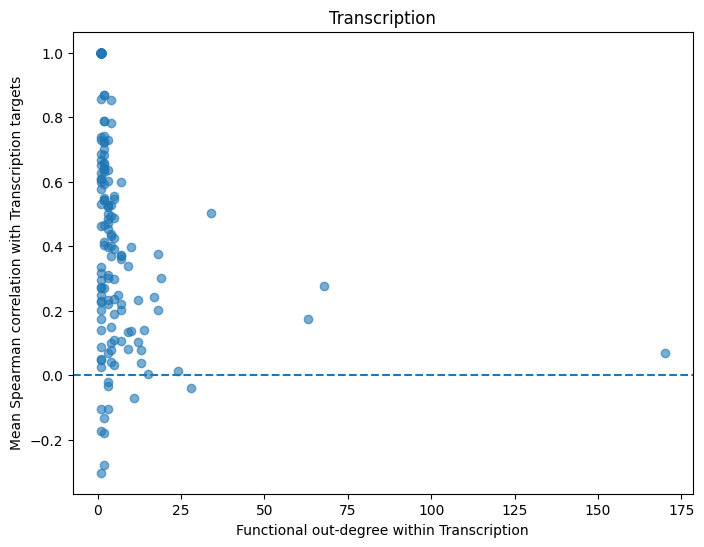

In [ ]:
# Select Transcription function

transcription_df = trn_function_summary_df[
    trn_function_summary_df["target_function"] == "Transcription"
].copy()

rho, p_value = spearmanr(
    transcription_df["function_out_degree"],
    transcription_df["mean_spearman_correlation"]
)

print("Number of regulators:", len(transcription_df))
print(f"Spearman rho = {rho:.4f}")
print(f"p-value = {p_value:.4e}")

plt.figure(figsize=(8, 6))

plt.scatter(
    transcription_df["function_out_degree"],
    transcription_df["mean_spearman_correlation"],
    alpha=0.6
)

plt.axhline(0, linestyle="--")

plt.xlabel("Functional out-degree within Transcription")
plt.ylabel("Mean Spearman correlation with Transcription targets")
plt.title("Transcription")
plt.show()

In [ ]:
# Transcription: activation / repression composition for each regulator

# 1. Keep only targets belonging to Transcription
transcription_effect_df = trn_target_function_df[
    trn_target_function_df["target_function"] == "Transcription"
].copy()

# 2. Count activation / repression targets for each regulator
transcription_effect_summary = (
    transcription_effect_df
    .groupby(["regulator_id", "effect"])
    ["target_id"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# 3. Functional out-degree = total number of unique
#    Transcription targets regulated by this regulator
transcription_effect_summary["function_out_degree"] = (
    transcription_effect_df
    .groupby("regulator_id")["target_id"]
    .nunique()
    .reindex(transcription_effect_summary["regulator_id"])
    .values
)

# 4. Sort from highest functional out-degree
transcription_effect_summary = (
    transcription_effect_summary
    .sort_values("function_out_degree", ascending=False)
    .reset_index(drop=True)
)

display(transcription_effect_summary.head(20))

effect,regulator_id,activation,repression,unknown,function_out_degree
0,b3067,170,0,0,170
1,b3357,48,11,9,68
2,b1988,14,47,1,63
3,b2741,34,0,0,34
4,b0889,13,6,9,28
5,b1334,11,10,3,24
6,b4401,10,9,0,19
7,b2664,7,11,0,18
8,b0683,2,15,1,18
9,b3202,16,1,0,17


In [49]:
# Examine individual Transcription interactions for b3067

b3067_transcription = trn_function_pair_df[
    (trn_function_pair_df["regulator_id"] == "b3067") &
    (trn_function_pair_df["target_function"] == "Transcription")
].copy()

display(
    b3067_transcription[
        [
            "regulator_id",
            "target_id",
            "target_function",
            "effect",
            "pearson_correlation",
            "spearman_correlation"
        ]
    ]
    .sort_values("spearman_correlation")
    .head(15)
)

,regulator_id,target_id,target_function,effect,pearson_correlation,spearman_correlation
5605,b3067,b1823,Transcription,activation,-0.612596,-0.659803
5313,b3067,b0889,Transcription,activation,-0.499759,-0.549799
5541,b3067,b1594,Transcription,activation,-0.571033,-0.547426
5020,b3067,b0034,Transcription,activation,-0.532609,-0.488213
5234,b3067,b0623,Transcription,activation,-0.373837,-0.454935
5206,b3067,b0564,Transcription,activation,-0.445768,-0.436186
5980,b3067,b3022,Transcription,activation,-0.247921,-0.423191
5655,b3067,b1951,Transcription,activation,-0.481870,-0.375740
6484,b3067,b4312,Transcription,activation,-0.439997,-0.374142
6404,b3067,b4089,Transcription,activation,-0.375008,-0.337918


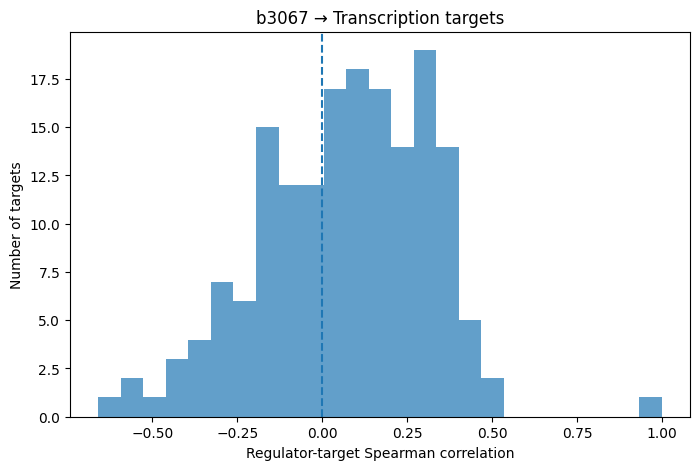

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    b3067_transcription["spearman_correlation"].dropna(),
    bins=25,
    alpha=0.7
)

plt.axvline(0, linestyle="--")

plt.xlabel("Regulator-target Spearman correlation")
plt.ylabel("Number of targets")
plt.title("b3067 → Transcription targets")
plt.show()
# Here, high-degree regulators may control targets across diverse regulatory contexts 
# rather than a single co-expressed module. (different from String dataset analysis)
# Therefore, the even targets sharing the same regulatory effect (here, activation) 
# can show heterogeneous expression correlations across environments

# STRING: physical complex -> high degree can mean strong coordination and 
# even a specific molecular function (e.g., flagellar machinery)

# TRN: broad regulatory control -> high degree can mean heterogeneous coordination. 